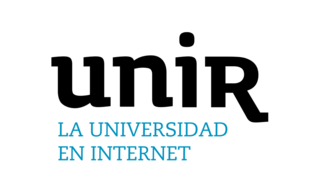

_Aprendizaje Automático_

_AI Engineering Portfolio_

# Actividad: Clasificación con máquinas de vectores de soporte y random forest

## Objetivos

Mediante esta actividad se pretende que ponga en práctica la creación de modelos basados en máquinas de vector de soporte y random forest. El objetivo es comprender de forma práctica con un problema determinado las diferencias que existen a la hora de entrenar los diferentes modelos.

- Comprender el tratamiento de datos que hay que realizar para los modelos de clasificación.
- Entender y aplicar el algoritmo de Random Forest a un problema de clasificación.
- Entender y aplicar el algoritmo de Support Vector Machine a un problema de clasificación.
- Evaluar y analizar los resultados de los clasificadores.
- Investigar la aplicación de los modelos de clasificación a problemas reales.


## Descripción de la actividad

Debes completar los espacios indicados en el notebook con el código solicitado y la respuesta, en función de lo que se solicite. Ten encuenta que las celdas vacías indican cuántas líneas debe ocupar la respuesta, por lo general no más de una línea.

El conjunto de datos con el que vamos a trabajar se encuentra en el siguiente enlace: https://archive.ics.uci.edu/dataset/31/covertype

Este dataset ha sido generado para predecir el tipo de cubierta forestal únicamente a partir de variables cartográficas (sin datos de sensores remotos). El tipo de cubierta forestal real para una observación determinada (celda de 30 x 30 metros) se determinó a partir de los datos del Sistema de información de recursos (RIS) de la Región 2 del Servicio Forestal de EE. UU. (USFS). Las variables independientes se derivaron de datos obtenidos originalmente del Servicio Geológico de EE. UU. (USGS) y de datos del USFS. Los datos están en forma original (no escalados) y contienen columnas binarias (0 o 1) de datos para variables cualitativas independientes (áreas silvestres y tipos de suelo).
Para ampliar información sobre el dataset y su origen, recomendamos leer la descripción completa del dataset en el enlace del repositorio. l.

El objetivo de la clasificación será detectar el tipo de suelo.

### Tareas que se deben realizar

- Análisis descriptivo de los datos:
   - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Clasificación:
  - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Investigación:
  - Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de clasificación empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.
  - Para el artículo indicar:
    - Objetivo: cuál es el objetivo de la investigación, es decir a qué problema real está aplicando la clasificación.
    - Cómo utilizan las técnicas de clasificación, si realizan alguna adaptación de los algoritmos indicarse.
    - Principales resultados de la aplicación y de la investigación.


### Análisis descriptivo de los datos

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from pandas import DataFrame
from sklearn.svm import SVC

In [2]:
# se carga el dataset
df = pd.read_csv('data.csv')
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


¿Cuántas instancias de datos tiene el dataset?

In [3]:
print(f"Instancias (filas): {df.shape[0]}")

Instancias (filas): 581012


¿Cuántas variables continuas hay en el dataset?

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Wilderness_Area2                    581012 non-null 

 No hay ninguna variable continua en el dataset

¿Cuántas variables categóricas hay en el dataset? Indica las categorías.

In [5]:
# Nombre de variable y sus valores unicos
for col in df.columns:
    x = df[col].nunique()
    print(f"{col}: {x}")

Elevation: 1978
Aspect: 361
Slope: 67
Horizontal_Distance_To_Hydrology: 551
Vertical_Distance_To_Hydrology: 700
Horizontal_Distance_To_Roadways: 5785
Hillshade_9am: 207
Hillshade_Noon: 185
Hillshade_3pm: 255
Horizontal_Distance_To_Fire_Points: 5827
Wilderness_Area1: 2
Wilderness_Area2: 2
Wilderness_Area3: 2
Wilderness_Area4: 2
Soil_Type1: 2
Soil_Type2: 2
Soil_Type3: 2
Soil_Type4: 2
Soil_Type5: 2
Soil_Type6: 2
Soil_Type7: 2
Soil_Type8: 2
Soil_Type9: 2
Soil_Type10: 2
Soil_Type11: 2
Soil_Type12: 2
Soil_Type13: 2
Soil_Type14: 2
Soil_Type15: 2
Soil_Type16: 2
Soil_Type17: 2
Soil_Type18: 2
Soil_Type19: 2
Soil_Type20: 2
Soil_Type21: 2
Soil_Type22: 2
Soil_Type23: 2
Soil_Type24: 2
Soil_Type25: 2
Soil_Type26: 2
Soil_Type27: 2
Soil_Type28: 2
Soil_Type29: 2
Soil_Type30: 2
Soil_Type31: 2
Soil_Type32: 2
Soil_Type33: 2
Soil_Type34: 2
Soil_Type35: 2
Soil_Type36: 2
Soil_Type37: 2
Soil_Type38: 2
Soil_Type39: 2
Soil_Type40: 2
Cover_Type: 7


Conceptualmente existen **3 variables categóricas** en el dataset (2 variables predictoras independientes y 1 variable objetivo).

Sin embargo, debido a que las predictoras ya están preprocesadas con *One-Hot Encoding* (codificación binaria), estas se presentan desglosadas en 44 columnas físicas distintas + 1 columna para el objetivo.

A continuación se detallan las categorías de cada una:

#### 1. Áreas Silvestres (Wilderness Areas)
* **Formato en el dataset:** 4 columnas binarias (`Wilderness_Area1` a `Wilderness_Area4`).
* **Categorías (4):**
    1.  Rawah Wilderness Area
    2.  Neota Wilderness Area
    3.  Comanche Peak Wilderness Area
    4.  Cache la Poudre Wilderness Area

#### 2. Tipos de Suelo (Soil Types)
* **Formato en el dataset:** 40 columnas binarias (`Soil_Type1` a `Soil_Type40`).
* **Categorías (40):** Corresponden a 40 códigos únicos de Unidades Ecológicas de Tierra (ELU) del USFS. Describen la familia geológica, tipo de roca y condiciones climáticas del suelo.

#### 3. Tipo de Cubierta Forestal (Cover_Type) - *Variable Objetivo*
* **Formato en el dataset:** 1 columna de números enteros (`Cover_Type`) con valores del 1 al 7.
* **Categorías (7):**
    1.  **Spruce/Fir** (Abeto/Pícea)
    2.  **Lodgepole Pine** (Pino Contorta)
    3.  **Ponderosa Pine** (Pino Ponderosa)
    4.  **Cottonwood/Willow** (Álamo/Sauce)
    5.  **Aspen** (Álamo Temblón)
    6.  **Douglas-fir** (Abeto de Douglas)
    7.  **Krummholz** (Vegetación Subalpina)

¿Cómo es la distribución de etiquetas de clase en el dataset? Con estos datos, ¿podríamos decir que el dataset está balanceado?

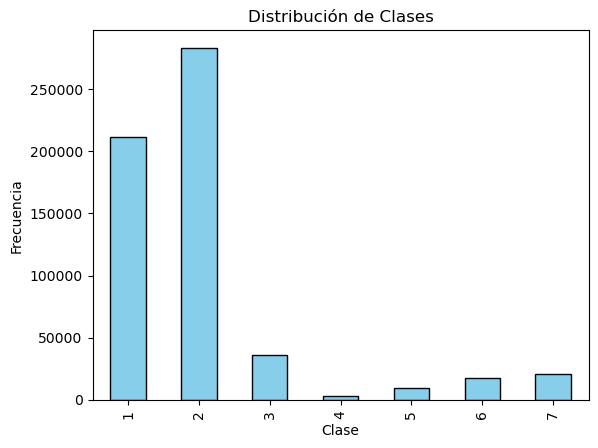

In [6]:
df['Cover_Type'].value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')

plt.title("Distribución de Clases")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.show()

In [7]:
print(df['Cover_Type'].value_counts())

Cover_Type
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64


La distribución de las etiquetas de clase (`Cover_Type`) **no es uniforme**. Al analizar el gráfico de barras y las frecuencias absolutas, observamos lo siguiente:

1.  **Dominancia de dos clases:** Las clases **2** (283.301 muestras) y **1** (211.840 muestras) representan la inmensa mayoría de los datos.
2.  **Escasez de datos en otras clases:** Las clases 3, 4, 5, 6 y 7 tienen una representación mucho menor.
3.  **El caso extremo:** La clase **4** cuenta con apenas 2.747 muestras.

**El dataset está fuertemente desbalanceado.**

Existe una desproporción drástica entre la clase mayoritaria (Clase 2) y la minoritaria (Clase 4), donde la Clase 2 tiene **más de 100 veces** la cantidad de datos que la Clase 4. Esto indica que cualquier modelo predictivo tendrá un sesgo natural hacia predecir las clases 1 y 2 si no se aplican técnicas de balanceo.

¿Existen valores nulos o perdidos en el dataset?

In [8]:
total_nulos = df.isnull().sum().sum()
print(f"Cantidad total de valores nulos en el dataset: {total_nulos}")

Cantidad total de valores nulos en el dataset: 0


No, no existen valores nulos ni perdidos en el dataset.

¿Existe alguna variable altamente correlacionada con la variable de clase?

_Nota: Para responder a esto, como es muy dificil ver la matriz de correlaciones, recomendamos filtrar aquellas correlaciones superiores al 0.80 con la variable de clase.

In [9]:
# Correlación de todas las columnas del dataframe con 'Cover_Type'
correlaciones_todas = df.corr()['Cover_Type'].drop('Cover_Type')

# Ordenar por valor absoluto
top_5_todas = correlaciones_todas.iloc[correlaciones_todas.abs().argsort()[::-1]].head(5)

print("--- TOP 5 VARIABLES CON MAYOR CORRELACIÓN ---")
print(top_5_todas)

--- TOP 5 VARIABLES CON MAYOR CORRELACIÓN ---
Wilderness_Area4    0.323200
Elevation          -0.269554
Soil_Type10         0.243876
Wilderness_Area1   -0.203913
Soil_Type38         0.160170
Name: Cover_Type, dtype: float64


**No.** Tras analizar la correlación de todas las variables del dataset con la variable objetivo `Cover_Type`, **ninguna supera el umbral de 0.80** en valor absoluto.

¿Qué tres variables del dataset consideras que pueden influenciar más en la clasificación de los datos?¿Qué pruebas harías para comprobar tus hipótesis? Hazlas.

In [10]:
print("Entrenando modelo juez...")
# Usamos una muestra del 20% para ir rápido
subset = df.sample(frac=0.2, random_state=42)
X = subset.drop('Cover_Type', axis=1)
y = subset['Cover_Type']

# Entrenamos
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

# Sacamos el Top 10 real
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

print("\n--- RANKING REAL DE IMPORTANCIA (Random Forest) ---")
print(importancias)

Entrenando modelo juez...

--- RANKING REAL DE IMPORTANCIA (Random Forest) ---
Elevation                             0.232590
Horizontal_Distance_To_Roadways       0.107911
Horizontal_Distance_To_Fire_Points    0.100211
Horizontal_Distance_To_Hydrology      0.061167
Vertical_Distance_To_Hydrology        0.058430
Aspect                                0.052578
Hillshade_Noon                        0.048813
Hillshade_3pm                         0.047732
Hillshade_9am                         0.046988
Slope                                 0.038384
dtype: float64


Tras contrastar las métricas de correlación lineal con un modelo no-lineal (Random Forest), determino que las tres variables con mayor influencia real en la clasificación son:

1.  **Elevation (Importancia: 0.2325):**
    Es el factor dominante. Su importancia es más del doble que la de cualquier otra variable. Determina las zonas bioclimáticas donde pueden sobrevivir las distintas especies.

2.  **Horizontal_Distance_To_Roadways (Importancia: 0.1079):**
    A pesar de tener una correlación lineal baja, el modelo la identifica como la segunda variable más crítica. Esto sugiere que la accesibilidad y la ubicación relativa a la infraestructura humana dividen eficazmente los tipos de bosque de manera no lineal.

3.  **Horizontal_Distance_To_Fire_Points (Importancia: 0.1002):**
    Muy cerca de la distancia a carreteras, esta variable confirma que la geografía histórica (puntos de incendio) es un predictor mucho más robusto que el tipo de suelo específico.

La prueba ha demostrado que guiarse solo por la correlación de Pearson (que sugería `Wilderness_Area4` o `Soil_Type10`) es engañoso en este dataset.

In [11]:
# Separamos los datos en los conjuntos de entrenamiento y test.
from sklearn.model_selection import train_test_split

X, y = df.drop('Cover_Type',axis=1),df['Cover_Type']

X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.8, random_state=1)

### Clasificación

**Random Forest**

En esta parte de la actividad hay que utilizar la librería https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html para resolver el problema de clasificación.

El algortimo de RF necesitar ajustar una serie de hiperparámetros para realizar las clasificaciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de clasificación, nos tenemos que preocupar de los siguientes hiperparámetros:
- n_estimators
- criterion
- max_depth
- min_samples_split
- min_samples_leaf
- max_features

Indica qué son cada uno de estos hiperparámetros

#### 1. `n_estimators` (Número de estimadores)
* **Definición:** Es el número de árboles de decisión individuales que compondrán el bosque.
* **Funcionamiento:** El algoritmo entrena esta cantidad de árboles independientes. La predicción final se obtiene por votación mayoritaria (en clasificación) o promediando (en regresión) las predicciones de todos ellos.
* **Impacto:** Generalmente, un número mayor aumenta la estabilidad y precisión del modelo y reduce el riesgo de *overfitting*, pero también incrementa linealmente el tiempo de cómputo.

#### 2. `criterion` (Criterio)
* **Definición:** Es la función matemática utilizada para medir la calidad de una división (split) en cada nodo del árbol. Determina qué variable y qué umbral son los "mejores" para separar los datos.
* **Opciones comunes:**
    * `"gini"`: Mide la impureza de Gini. Es más rápido de calcular y busca minimizar la probabilidad de clasificar incorrectamente un elemento aleatorio.
    * `"entropy"`: Mide la ganancia de información (basada en la teoría de la información de Shannon). Busca reducir la incertidumbre (entropía) en los nodos hijos.

#### 3. `max_depth` (Profundidad máxima)
* **Definición:** Es la longitud máxima del camino desde la raíz hasta la hoja más lejana. Limita cuánto puede crecer el árbol verticalmente.
* **Impacto:**
    * **Valores altos (o None):** El árbol puede crecer indefinidamente hasta clasificar perfectamente los datos de entrenamiento. Esto captura relaciones complejas pero tiene un **alto riesgo de overfitting** (memorización).
    * **Valores bajos:** El modelo es más simple y generalista, pero si es demasiado bajo puede sufrir de *underfitting* (no aprende lo suficiente).

#### 4. `min_samples_split` (Muestras mínimas para dividir)
* **Definición:** Es el número mínimo de muestras necesarias en un nodo interno para que se permita realizar una nueva división.
* **Funcionamiento:** Si un nodo contiene menos muestras que este valor, se convierte en una hoja y deja de crecer, independientemente de su impureza.
* **Impacto:** Valores más altos evitan que el árbol aprenda relaciones demasiado específicas (ruido) de grupos pequeños de datos, actuando como regularizador.

#### 5. `min_samples_leaf` (Muestras mínimas en hoja)
* **Definición:** Es el número mínimo de muestras que debe tener obligatoriamente un nodo final (hoja) después de una división.
* **Funcionamiento:** Si una división potencial fuera a dejar un nodo hijo con menos muestras que este umbral, dicha división se prohíbe.
* **Impacto:** Es muy efectivo para suavizar el modelo. Garantiza que ninguna decisión se base en uno o dos casos aislados (anomalías o *outliers*), reduciendo significativamente el *overfitting*.

#### 6. `max_features` (Máximo de características)
* **Definición:** El número de características (columnas) que el algoritmo considera al buscar la mejor división en cada nodo.
* **La clave del Random Forest:** En lugar de evaluar todas las variables posibles en cada paso, selecciona un subconjunto aleatorio.
* **Impacto:**
    * Aumenta la diversidad entre los árboles del bosque (descorrelación), lo que mejora el rendimiento global del conjunto.
    * Si el valor es bajo, los árboles son muy diferentes entre sí. Si es alto (o igual al total de features), los árboles tienden a parecerse más.

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro _class_weight_

¿Qué indica ese parámetro? ¿Para qué puede ser útil?


El parámetro `class_weight` permite asignar una importancia (peso) diferente a cada clase durante el proceso de entrenamiento del modelo.

Por defecto, los algoritmos de Machine Learning asumen que todas las clases son igual de importantes (peso = 1). Sin embargo, al modificar este parámetro, le decimos al modelo que **penalice más fuerte** los errores cometidos en ciertas clases que en otras.

Su utilidad principal es resolver el problema de los **Datasets Desbalanceados** (Imbalanced Data).

En el dataset *Cover_Type*, por ejemplo, las Clases 1 y 2 tienen miles de registros, mientras que la Clase 4 tiene muy pocos.
* **Sin `class_weight`:** El modelo puede volverse "perezoso" y aprender a predecir siempre las clases mayoritarias (1 y 2) ignorando la 4, logrando una alta precisión global (accuracy) pero fallando totalmente en la clase minoritaria.
* **Con `class_weight`:** El modelo se ve obligado a prestar atención a la clase minoritaria porque equivocarse en ella le "cuesta" más puntos de error matemáticamente.

**Opciones típicas en sklearn:**

1.  **`None` (Por defecto):** Todas las clases tienen peso 1.
2.  **`'balanced'`:** Calcula los pesos automáticamente de forma **inversamente proporcional** a la frecuencia de la clase.
    * Clase muy frecuente (Mayoritaria) $\rightarrow$ Peso bajo.
    * Clase muy rara (Minoritaria) $\rightarrow$ Peso alto.
    * *Fórmula:* $Peso = \frac{n\_muestras}{n\_clases \times n\_muestras\_clase}$
3.  **`'balanced_subsample'` (Específico de Random Forest):** Similar al anterior, pero calcula los pesos basándose en la muestra *bootstrap* de cada árbol individual, en lugar de usar el dataset completo global. Suele ser más robusto.

Como primer paso para crear un clasificador de Random Forest hay que decidir si hay que hacer algún preprocesamiento adicional sobre los datos.
¿Hace falta normalizar los datos?

**No, no hace falta normalizar ni estandarizar los datos** para entrenar un modelo de Random Forest.

A diferencia de otros algoritmos, los **modelos basados en árboles** (como Decision Trees, Random Forest o Gradient Boosting) son **invariantes a la escala** de las variables.

1.  **Funcionamiento por Reglas:** Los árboles funcionan haciendo preguntas lógicas de tipo "mayor que / menor que" (ej: *¿Es la Elevación > 2500m?*).
2.  **Independencia de la Escala:** Si cambiáramos la escala de la elevación de metros a kilómetros (ej: 2.5km), el árbol simplemente ajustaría el umbral de la pregunta (*¿Es la Elevación > 2.5km?*), pero el corte resultante dividiría los datos exactamente en los mismos grupos. No calcula distancias euclidianas.

Podemos introducir los datos "crudos" (raw data) directamente al modelo sin necesidad de aplicar `StandardScaler` o `MinMaxScaler`, simplificando el pipeline de preprocesamiento.

Entrena un conjunto de modelos de Random Forest que utilicen todas las variables del dataset, con 5, 10, 20, 50 y 100 árboles. El criterio para realizar las particiones debe ser Gini-index, la profundidad máxima de los árboles debe ser 10, el número mínimo de ejemplos para realizar una partición debe ser 10, el número mínimo de ejemplos para considerarlo una hoja debe ser 2, y el número máximo de características deben ser todas.

_Nota: el entrenamiento puede tardar entre 3 y 15 minutos en función de las características del equipo._

## Random Forest sin class_weight

In [12]:
# Definimos la lista de árboles
n_arboles_list = [5, 10, 20, 50, 100]

# Diccionario para almacenar los modelos ya entrenados
# Usamos un diccionario para poder acceder luego fácilmente: modelos_rf[50]
modelos_rf = {}

print("Iniciando entrenamiento de modelos...")

for n in n_arboles_list:
    print(f"   -> Entrenando Random Forest con {n} árboles...")
    
    # Configuramos el modelo con los hiperparámetros
    rf = RandomForestClassifier(
        n_estimators=n,
        criterion='gini',          # Criterio Gini
        max_depth=10,              # Profundidad máxima 10
        min_samples_split=10,      # Mínimo para dividir 10
        min_samples_leaf=2,        # Mínimo en hoja 2
        max_features=None,         # None significa "Tomar todas las características"
        random_state=42            # Semilla para resultados reproducibles
    )
    
    rf.fit(X_train, y_train)
    
    # Lo guardamos en el diccionario
    modelos_rf[n] = rf

print("¡Todos los modelos han sido entrenados correctamente!")

Iniciando entrenamiento de modelos...
   -> Entrenando Random Forest con 5 árboles...
   -> Entrenando Random Forest con 10 árboles...
   -> Entrenando Random Forest con 20 árboles...
   -> Entrenando Random Forest con 50 árboles...
   -> Entrenando Random Forest con 100 árboles...
¡Todos los modelos han sido entrenados correctamente!


Visualiza la matriz de confusión del modelo entrenado con 20 árboles.

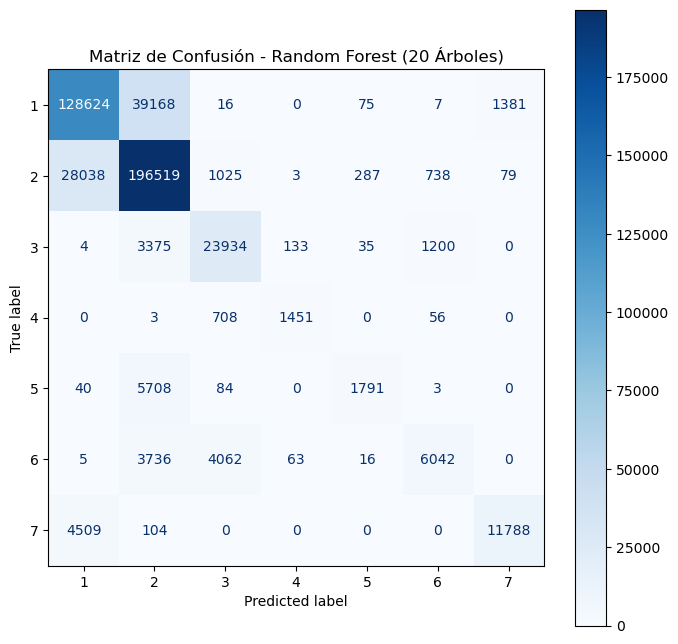

In [13]:
# Seleccionamos el modelo de 20 árboles
modelo_20 = modelos_rf[20]

# Configuramos el gráfico
fig, ax = plt.subplots(figsize=(8, 8))

# Generamos la matriz directamente desde el modelo y los datos de test
ConfusionMatrixDisplay.from_estimator(
    modelo_20,
    X_test,
    y_test,
    cmap='Blues',           # Color azul (más oscuro = más aciertos)
    values_format='d',      # Formato 'd' (enteros) para no ver notación científica
    ax=ax
)

plt.title("Matriz de Confusión - Random Forest (20 Árboles)")
plt.show()

¿Cuántos ejemplos ha clasificado correctamente?

In [14]:
predicciones = modelo_20.predict(X_test)
num_aciertos = (y_test == predicciones).sum()

print(f"Total de ejemplos en el Test Set: {len(y_test)}")
print(f"Ejemplos clasificados correctamente: {num_aciertos}")
print(f"Porcentaje de acierto (Accuracy): {num_aciertos / len(y_test) * 100:.2f}%")

Total de ejemplos en el Test Set: 464810
Ejemplos clasificados correctamente: 370149
Porcentaje de acierto (Accuracy): 79.63%


Explica cómo funciona la clasificación para cada una de las 7 clases. ¿Hay alguna clase que clasifica mejor que otras?

In [15]:
# Informe detallado del modelo de 20 árboles
print(classification_report(y_test, modelo_20.predict(X_test)))

              precision    recall  f1-score   support

           1       0.80      0.76      0.78    169271
           2       0.79      0.87      0.83    226689
           3       0.80      0.83      0.82     28681
           4       0.88      0.65      0.75      2218
           5       0.81      0.23      0.36      7626
           6       0.75      0.43      0.55     13924
           7       0.89      0.72      0.80     16401

    accuracy                           0.80    464810
   macro avg       0.82      0.64      0.70    464810
weighted avg       0.80      0.80      0.79    464810



La **Clase 2 (Lodgepole Pine)** es la "ganadora global".
* **F1-Score (0.83):** Es el más alto del conjunto.
* **Recall (0.87):** El modelo es capaz de encontrar el 87% de todos los pinos de este tipo.
* **Motivo:** Es la clase más abundante del dataset (226,689 ejemplos). El modelo ha tenido suficientes datos para aprender sus patrones a la perfección.

La **Clase 7 (Krummholz)** tiene la **Mejor Precisión (0.89)**. Cuando el modelo dice "esto es clase 7", acierta el 89% de las veces, probablemente porque vive en una elevación muy extrema y fácil de separar.

La **Clase 5 (Aspen)** es la que peor funciona, con diferencia.
* **F1-Score (0.36):** Un resultado pésimo.
* **Recall (0.23):** El modelo **pierde casi el 80%** de los árboles de esta clase (no los detecta).
* **Motivo:** Tiene pocos datos (7,626) y probablemente sus características se solapan o confunden mucho con la Clase 1 o 2. Al no usar pesos (`class_weight`), el modelo prefiere fallar aquí antes que arriesgarse a equivocarse en las clases grandes.

A diferencia de lo esperado, la Clase 4 tiene una precisión muy alta (**0.88**), aunque un recall bajo (0.65). Esto significa que el modelo es "conservador": se atreve poco a predecir la Clase 4, pero cuando lo hace, casi siempre acierta.

Existe un **sesgo claro hacia la Clase 2**. El modelo ha optimizado su rendimiento para acertar en la clase mayoritaria (que es lo que más sube la nota media), sacrificando casi por completo la capacidad de detectar las clases minoritarias "difíciles" como la 5 y la 6.

## Random Forest con class_weight

In [16]:
# Definimos la lista de árboles
n_arboles_list = [5, 10, 20, 50, 100]

# Diccionario para almacenar los modelos ya entrenados
modelos_rf_balanced = {}

print("Iniciando entrenamiento de modelos con Balanceo de Clases...")

for n in n_arboles_list:
    print(f"   -> Entrenando Random Forest (Balanced) con {n} árboles...")
    
    # Configuramos el modelo con los hiperparámetros + class_weight
    rf = RandomForestClassifier(
        n_estimators=n,
        criterion='gini',           # Criterio Gini
        max_depth=10,               # Profundidad máxima 10
        min_samples_split=10,       # Mínimo para dividir 10
        min_samples_leaf=2,         # Mínimo en hoja 2
        max_features=None,          # Todas las características
        class_weight='balanced_subsample', # El algoritmo recalcula los pesos de las clases para cada árbol individualmente
        random_state=42,            # Semilla
        n_jobs=-1                   # Usa todos los núcleos para ir más rápido
    )
    
    rf.fit(X_train, y_train)
    
    # Lo guardamos en el diccionario
    modelos_rf_balanced[n] = rf

print("¡Todos los modelos balanceados han sido entrenados correctamente!")

Iniciando entrenamiento de modelos con Balanceo de Clases...
   -> Entrenando Random Forest (Balanced) con 5 árboles...
   -> Entrenando Random Forest (Balanced) con 10 árboles...
   -> Entrenando Random Forest (Balanced) con 20 árboles...
   -> Entrenando Random Forest (Balanced) con 50 árboles...
   -> Entrenando Random Forest (Balanced) con 100 árboles...
¡Todos los modelos balanceados han sido entrenados correctamente!


In [17]:
# Seleccionamos el modelo balanceado de 20 árboles
modelo_balanceado_20 = modelos_rf_balanced[20]
print(classification_report(y_test, modelo_balanceado_20.predict(X_test)))

              precision    recall  f1-score   support

           1       0.75      0.73      0.74    169271
           2       0.84      0.63      0.72    226689
           3       0.82      0.73      0.77     28681
           4       0.62      0.89      0.73      2218
           5       0.15      0.91      0.26      7626
           6       0.42      0.81      0.56     13924
           7       0.54      0.93      0.68     16401

    accuracy                           0.70    464810
   macro avg       0.59      0.80      0.64    464810
weighted avg       0.77      0.70      0.72    464810



Al introducir el balanceo de pesos, hemos obligado al modelo a "robarle" protagonismo a las clases ricas (1 y 2) para dárselo a las pobres (4 y 5).

**1. El Rescate de la Clase 5 (Aspen):**
* **Antes:** Recall de **0.23**. El modelo ignoraba casi el 80% de estos árboles.
* **Ahora:** Recall de **0.91**. El modelo detecta el 91% de ellos.
* **El Coste:** La precisión ha caído a **0.15**. Para no perderse ningún Aspen, el modelo se ha vuelto "paranoico" y predice Aspen muy a menudo, generando muchos falsos positivos.

**2. El sacrificio de la Precisión Global:**
* **Accuracy:** Ha bajado del **80%** al **70%**.
* **Causa:** La Clase 2 (la más abundante) ha pasado de un Recall de 0.87 a **0.63**. Como la Clase 2 es la que más pesa en el promedio, al fallar más en ella, la nota global baja.

## Resultados

¿Cuál de todos los modelos que has entrenado obtiene mejores resultados de precisión para el conjunto de datos de test?

_Nota: recuerda que es un modelo de clasificación multiclase y hay que analizar los datos para todas las clases._

In [18]:
# Resultados de los modelos sin balancear
resultados = []

for n, modelo in modelos_rf.items():
    acc = modelo.score(X_test, y_test)
    resultados.append({
        "Modelo": f"RF {n} Árboles (Normal)",
        "Accuracy": acc,
        "Tipo": "Sin Balancear"
    })

# Añadimos el modelo balanceado (del diccionario modelos_rf_balanced)
if 'rf_balanced' in locals():
    acc_bal = rf_balanced.score(X_test, y_test)
    resultados.append({
        "Modelo": "RF 100 Árboles (Balanceado)",
        "Accuracy": acc_bal,
        "Tipo": "Balanceado"
    })

# Creamos un DataFrame
df_resultados = pd.DataFrame(resultados).sort_values(by="Accuracy", ascending=False)

print("--- RANKING FINAL DE PRECISIÓN ---")
print(df_resultados.to_string(index=False))

--- RANKING FINAL DE PRECISIÓN ---
                 Modelo  Accuracy          Tipo
RF 100 Árboles (Normal)  0.799673 Sin Balancear
 RF 50 Árboles (Normal)  0.797786 Sin Balancear
 RF 20 Árboles (Normal)  0.796345 Sin Balancear
 RF 10 Árboles (Normal)  0.796087 Sin Balancear
  RF 5 Árboles (Normal)  0.792276 Sin Balancear



El modelo que obtiene los mejores resultados de precisión global (*Accuracy*) es el **Random Forest de 100 Árboles (Sin Balancear)**, con un acierto del **79.97%**.

1.  **Más árboles = Mejor rendimiento:** Existe una mejora progresiva a medida que aumentamos el número de estimadores (de 79.22% con 5 árboles a 79.97% con 100). Cuantos más árboles "votan", más se reducen los errores individuales y la varianza del modelo.
2.  **Rendimiento decreciente:** La diferencia entre el modelo de 50 árboles (79.78%) y el de 100 árboles (79.97%) es mínima (menos del 0.2%). Esto indica que seguir añadiendo árboles (ej. 500 o 1000) probablemente solo aumentaría el coste computacional sin ofrecer una mejora significativa en la precisión.

Selecciona el modelo que consideras que obtiene mejores resultados para los resultados de test. Explica por qué consideras que ese modelo es el que mejor resultados obtiene.

In [19]:
# Seleccionamos el modelo de 100 árboles
modelo_100 = modelos_rf[100]
print(classification_report(y_test, modelo_100.predict(X_test)))

              precision    recall  f1-score   support

           1       0.80      0.77      0.78    169271
           2       0.79      0.87      0.83    226689
           3       0.80      0.84      0.82     28681
           4       0.87      0.66      0.75      2218
           5       0.84      0.23      0.36      7626
           6       0.75      0.44      0.55     13924
           7       0.90      0.72      0.80     16401

    accuracy                           0.80    464810
   macro avg       0.82      0.64      0.70    464810
weighted avg       0.80      0.80      0.79    464810



In [20]:
# Seleccionamos el modelo balanceado de 100 árboles
modelo_balanceado_100 = modelos_rf_balanced[100]
print(classification_report(y_test, modelo_balanceado_100.predict(X_test)))

              precision    recall  f1-score   support

           1       0.76      0.73      0.75    169271
           2       0.84      0.63      0.72    226689
           3       0.82      0.74      0.78     28681
           4       0.64      0.89      0.74      2218
           5       0.15      0.91      0.26      7626
           6       0.42      0.82      0.56     13924
           7       0.55      0.93      0.69     16401

    accuracy                           0.70    464810
   macro avg       0.60      0.81      0.64    464810
weighted avg       0.77      0.70      0.72    464810



El modelo que obtiene los mejores resultados globales es el **Random Forest de 100 árboles (Standard / Sin Balancear)**.

1.  **Superioridad en Exactitud (Accuracy):**
    Este modelo alcanza una exactitud del **80%**, superando por 10 puntos porcentuales al modelo balanceado (70%). En clasificación general, esta diferencia es masiva y determinante.

2.  **Mejor equilibrio Precisión/Recall (F1-Score):**
    Si observamos el promedio *Macro Avg* del F1-Score (que trata a todas las clases por igual), el modelo estándar también gana (**0.70** vs **0.64**).
    * Aunque el modelo balanceado logra un Recall espectacular en la Clase 5 (0.91), su Precisión se desploma a **0.15**. Esto significa que para encontrar los árboles de Clase 5, el modelo balanceado genera una cantidad inmensa de "falsos positivos" (ruido), lo cual penaliza su puntuación general de calidad (F1).

3.  **Robustez General:**
    El modelo estándar es más confiable. Aunque omite muchos árboles de la Clase 5 (Recall 0.23), cuando hace una predicción, suele acertar (Precisión > 0.75 en casi todas las clases). El modelo balanceado, en cambio, se vuelve muy inestable en las clases minoritarias.


Visualiza la matriz de confusión de los datos de test de este modelo.
- ¿Cuántos ejemplos ha clasificado bien el modelo?
- ¿Cuántos ejemplos ha clasificado de manera errónea?

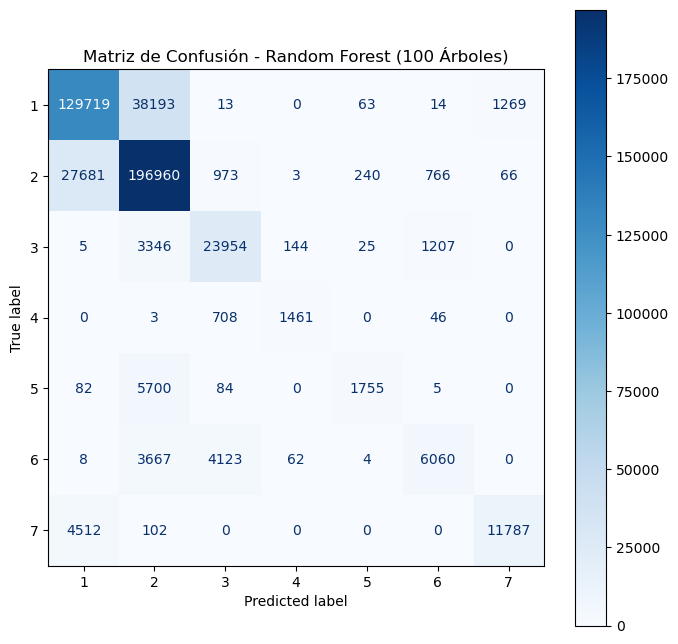

------------------------------
Resultados del Modelo Final:
✅ Ejemplos clasificados BIEN: 371696 (79.97%)
❌ Ejemplos clasificados MAL:  93114 (20.03%)
------------------------------


In [21]:
# Seleccionamos el mejor modelo (100 árboles sin balancear)
modelo_final = modelos_rf[100]

# Visualizamos la Matriz de Confusión
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_estimator(
    modelo_final,
    X_test,
    y_test,
    cmap='Blues',
    values_format='d',  # 'd' para ver números enteros sin notación científica
    ax=ax
)
plt.title("Matriz de Confusión - Random Forest (100 Árboles)")
plt.show()

# Calculamos las cifras exactas
y_pred = modelo_final.predict(X_test)
bien_clasificados = (y_test == y_pred).sum()
mal_clasificados = (y_test != y_pred).sum()
total = len(y_test)

print("-" * 30)
print(f"Resultados del Modelo Final:")
print(f"✅ Ejemplos clasificados BIEN: {bien_clasificados} ({bien_clasificados/total:.2%})")
print(f"❌ Ejemplos clasificados MAL:  {mal_clasificados} ({mal_clasificados/total:.2%})")
print("-" * 30)

Visualiza los valores de precision, recall, f1 para cada una de las clases. 
- ¿Clasifica de igual manera todas las clases o hay alguna para la que el modelo tiene una mayor capacidad predictiva?

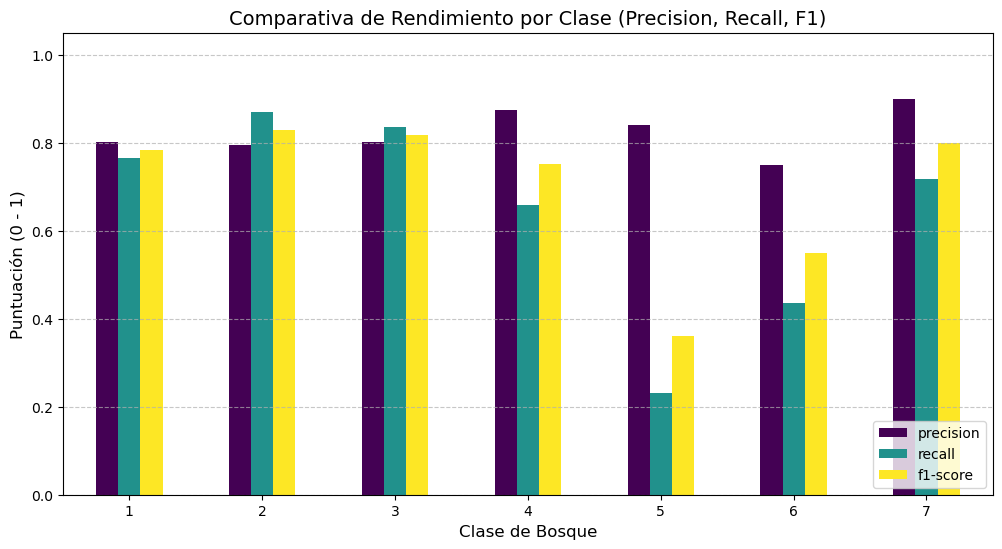

In [22]:
# Obtenemos el reporte en formato diccionario para poder graficarlo
report_dict = classification_report(y_test, modelo_100.predict(X_test), output_dict=True)

# Convertimos a DataFrame
df_report = pd.DataFrame(report_dict).transpose()
df_classes = df_report.drop(['accuracy', 'macro avg', 'weighted avg'])

# 3. Creamos el gráfico visual
df_classes[['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(12, 6), colormap='viridis')

plt.title('Comparativa de Rendimiento por Clase (Precision, Recall, F1)', fontsize=14)
plt.xlabel('Clase de Bosque', fontsize=12)
plt.ylabel('Puntuación (0 - 1)', fontsize=12)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.xticks(rotation=0)

plt.show()

**No.** Existe una clara desigualdad en la capacidad predictiva del modelo dependiendo de la clase.

1.  **Las Clases Mejor Clasificadas:**
    * **Clase 2 (Lodgepole Pine):** Es la "favorita" del modelo. Obtiene el mejor equilibrio general (**F1-Score: 0.83**) y un Recall del **87%**. Al ser la clase mayoritaria, el modelo ha aprendido a identificarla con gran solvencia.
    * **Clase 7 (Krummholz):** Destaca por tener la **Mejor Precisión (0.90)**. Esto significa que el modelo es muy fiable cuando predice esta clase (apenas comete falsos positivos), probablemente porque sus características geográficas (elevación extrema) son muy distintivas.

2.  **Las Clases Peor Clasificadas:**
    * **Clase 5 (Aspen):** Es el punto débil del sistema. Aunque la precisión es alta (0.84), el **Recall es crítico (0.23)**. El modelo ignora el **77%** de los árboles de esta clase, confundiéndolos con otros tipos.
    * **Clase 6 (Douglas-fir):** También presenta un rendimiento mediocre (F1-Score: 0.55), quedándose en "tierra de nadie".

El modelo maximiza su acierto global (80%) especializándose en las clases abundantes (1 y 2), mientras sacrifica la detección de las clases minoritarias (especialmente la 5), lo que confirma que el desbalanceo de datos sigue afectando al rendimiento detallado a pesar de usar un Random Forest robusto.

## Support Vector Machine

In [23]:
# Importamos las librerías para utilizar las máquinas de vector de soportes.
# Utilizaremos la librería svm:

from sklearn import svm

#Cargamos también las librerías para hacer la matriz de confusión y la cross validation:

from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import KFold

Para la implementación del modelo de clasificación de SVM usaremos la clase Support Vector Classifier de sklearn, https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

El algoritmo de SVM necesita ajustar una serie de hiperparámetros para realizar las clasificaciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de clasificación, nos tenemos que preocupar de los siguientes hiperparámetros:
- C
- kernel
- degree
- gamma

Indica qué son cada uno de estos hiperparámetros

**`C` (Parámetro de Regularización)**

Controla el equilibrio entre conseguir una clasificación perfecta en los datos de entrenamiento y tener una frontera de decisión suave. Es el "coste" o penalización por equivocarse.

* **¿Qué hace?** Determina la rigidez del margen.
* **C Bajo (ej. 0.1, 1):** Es más "permisivo". Acepta cometer errores de clasificación en el entrenamiento si a cambio consigue una frontera más simple (mayor generalización). *Riesgo: Underfitting.*
* **C Alto (ej. 100, 1000):** Es "estricto". Intenta clasificar correctamente todos los puntos, haciendo la frontera muy compleja si es necesario. *Riesgo: Overfitting.*

> **Analogía:** Un auditor técnico riguroso. Un **C bajo** es benévolo y perdona detalles; un **C alto** es estricto y baja puntos por todo.

---

**`kernel` (Tipo de Núcleo)**

Es la función matemática que transforma los datos de entrada en un espacio de mayor dimensión para poder separarlos.

* **¿Qué hace?** Decide la "forma" de la frontera de decisión.
* **`'linear'`:** Dibuja una línea recta o plano. Rápido y útil para muchas variables.
* **`'rbf'` (Radial Basis Function):** El valor por defecto. Crea fronteras curvas y cerradas. Es el más versátil.
* **`'poly'`:** Crea fronteras basadas en polinomios (curvas complejas).
* **`'sigmoid'`:** Similar a las redes neuronales.

---

**`degree` (Grado del Polinomio)**

Este parámetro **solo se utiliza si el kernel es `'poly'`**.

* **¿Qué hace?** Controla la complejidad de las curvas polinómicas.
* **Grado 1:** Equivalente a una recta.
* **Grado 2:** Curvas parabólicas.
* **Grado 3+:** Curvas complejas y flexibles. (Un grado muy alto suele llevar a *overfitting*).

---

**`gamma` (Coeficiente del Kernel)**
Se utiliza en kernels no lineales (`rbf`, `poly`, `sigmoid`). Define "hasta dónde llega la influencia" de un solo punto de entrenamiento.

* **¿Qué hace?** Controla el radio de influencia de los vectores de soporte.
* **Gamma Bajo (ej. 'auto'):** "Lejos". La influencia de un punto llega muy lejos, generando fronteras suaves y agrupadas.
* **Gamma Alto (ej. 'scale'):** "Cerca". La influencia se limita a la zona inmediata del punto, creando "islas" ajustadas a los datos. *Riesgo: Overfitting extremo.*

> **Analogía:** Un foco de luz. **Gamma bajo** es un foco de estadio (ilumina amplio). **Gamma alto** es un puntero láser (ilumina un punto exacto).

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro decision_function_shape

¿Qué indica ese parámetro? ¿Para qué puede ser útil?

Este parámetro es fundamental cuando trabajamos con problemas de **clasificación multiclase** (como este dataset, que tiene 7 tipos de bosque), ya que los algoritmos SVM son, por naturaleza, **clasificadores binarios** (solo saben separar "A" de "B").

**¿Qué indica?**
Indica la estrategia matemática que utilizará el modelo para romper un problema de muchas clases en varios problemas pequeños de dos clases.

**Valores posibles:**

* **`'ovo'` (One-vs-One / Uno contra Uno):**
    * Divide el problema entrenando un clasificador para cada **par de clases** posible.
    * Ejemplo: "Clase 1 vs Clase 2", "Clase 1 vs Clase 3", "Clase 2 vs Clase 3"...
    * Al final, la clase ganadora es la que recibe más votos de todos estos duelos individuales.
    * *Nota:* Genera muchos modelos ($N * (N-1) / 2$), pero son rápidos de entrenar porque usan pocos datos cada uno.

* **`'ovr'` (One-vs-Rest / Uno contra el Resto):**
    * Es el valor por defecto (y el más habitual).
    * Entrena un clasificador por cada clase, enfrentándola a **todas las demás juntas**.
    * Ejemplo: "Clase 1 vs Todo lo que no es 1", "Clase 2 vs Todo lo que no es 2"...
    * Gana la clase cuyo clasificador tenga mayor confianza.

**¿Para qué es útil?**
1.  **Interpretación:** Si usas `'ovr'`, la función de decisión te devuelve una puntuación limpia para cada clase (una matriz de tamaño `n_muestras, n_clases`), lo cual es más fácil de entender que ver los resultados de 21 duelos individuales.
2.  **Compatibilidad:** La mayoría de los otros algoritmos de Scikit-Learn funcionan con lógica `'ovr'`, por lo que usarla mantiene la coherencia al comparar modelos.

Tenemos un dataset de más de medio millón de instancias, y para el objetivo de la actividad no hacen falta tantas. Por eso, antes de aplicar SVM vamos a reducir el número de instancias. SVM requiere una gran carga computacional y con ese volumen de instancias el tiempo requerido sería demasiado elevado.

In [24]:
# Seleccionamos 80.000 muestras aleatorias
df_svm = df.sample(n=80000, random_state=42).copy()

Nota: recuerda revisar que esta manera de seleccionar un subconjunto de instancias no altera la clase objetivo. Deberías tener un porcentaje similar de instancias de cada clase. Si no fuera así, deberás cambiar la manera de seleccionar el subconjunto.

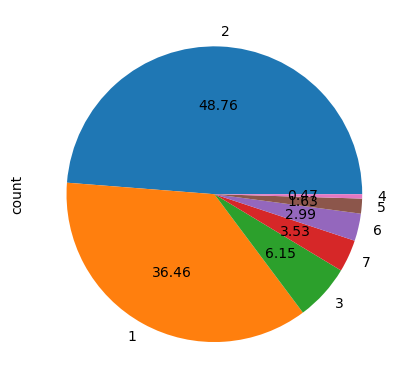

In [25]:
# Dataset original
df['Cover_Type'].value_counts().plot(kind='pie',autopct='%.2f',)
plt.show()

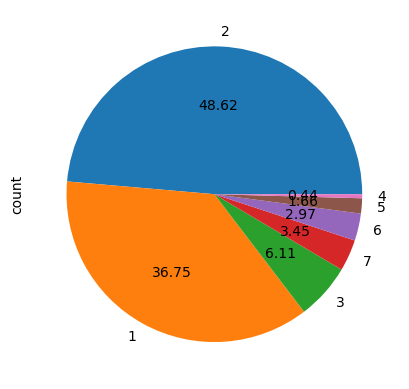

In [26]:
#Dataset aleatorizado con 100.000 muestras
df_svm['Cover_Type'].value_counts().plot(kind='pie',autopct='%.2f',)
plt.show()

In [27]:
# Con el nuevo número de instancias, separamos los datos en los conjuntos de entrenamiento y test.
from sklearn.model_selection import train_test_split

X, y = df_svm.drop('Cover_Type',axis=1),df_svm['Cover_Type']

X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.8, random_state=42)

Como primer paso para crear un clasificador de SVM hay que decidir si hay que hacer algún preprocesamiento adicional sobre los datos. ¿Hace falta normalizar los datos?

SVM es un algoritmo basado en distancias (geometría). Si no se normaliza, la variable "Elevation" (que vale miles) anulará por completo a variables como "Slope" (que vale decenas), y el modelo funcionará mal y lento.

In [28]:
scaler = StandardScaler()

# Ajustamos (aprendemos media/desviación) y transformamos el conjunto de TRAIN
X_train = scaler.fit_transform(X_train)

# Transformamos el conjunto de TEST usando los parámetros aprendidos en train
X_test = scaler.transform(X_test)

print("Datos normalizados correctamente (Media 0, Desviación 1)")
print(f"Ejemplo primera fila estandarizada: {X_train[0][:5]}...")

Datos normalizados correctamente (Media 0, Desviación 1)
Ejemplo primera fila estandarizada: [-0.10724609  0.88823395  0.91508376 -0.56436265 -0.43913334]...


Entrena un conjunto de modelos de SVM que utilicen todas las variables del dataset, con C = 0.1 hasta 1000 con cinco valores diferentes; kernel radial, y gamma con valor scale.

In [29]:
# 1. Definimos los hiperparámetros
# Usamos 5 valores en escala logarítmica para ver el efecto de la regularización
C_values = [0.1, 1, 10, 100, 1000] 
kernel = 'rbf'    # 'radial' se corresponde con 'rbf'
gamma = 'scale'

# Diccionario para guardar los modelos entrenados
modelos_svm = {}

print("Iniciando entrenamiento de SVM (Ten paciencia, puede tardar unos minutos)...")

for c in C_values:
    print(f"   -> Entrenando SVM con C={c}...")
    
    # Configuramos el modelo
    svc = SVC(
        C=c, 
        kernel=kernel, 
        gamma=gamma, 
        decision_function_shape='ovr', # Estándar para multiclase
        random_state=42
    )
    
    # Entrenamos
    svc.fit(X_train, y_train)
    
    # Guardamos el modelo en el diccionario
    modelos_svm[c] = svc

print("¡Todos los modelos SVM han sido entrenados!")

Iniciando entrenamiento de SVM (Ten paciencia, puede tardar unos minutos)...
   -> Entrenando SVM con C=0.1...
   -> Entrenando SVM con C=1...
   -> Entrenando SVM con C=10...
   -> Entrenando SVM con C=100...
   -> Entrenando SVM con C=1000...
¡Todos los modelos SVM han sido entrenados!


Después de hacer el entrenamiento, visualiza las matrices de confusión de los modelos entrenados.

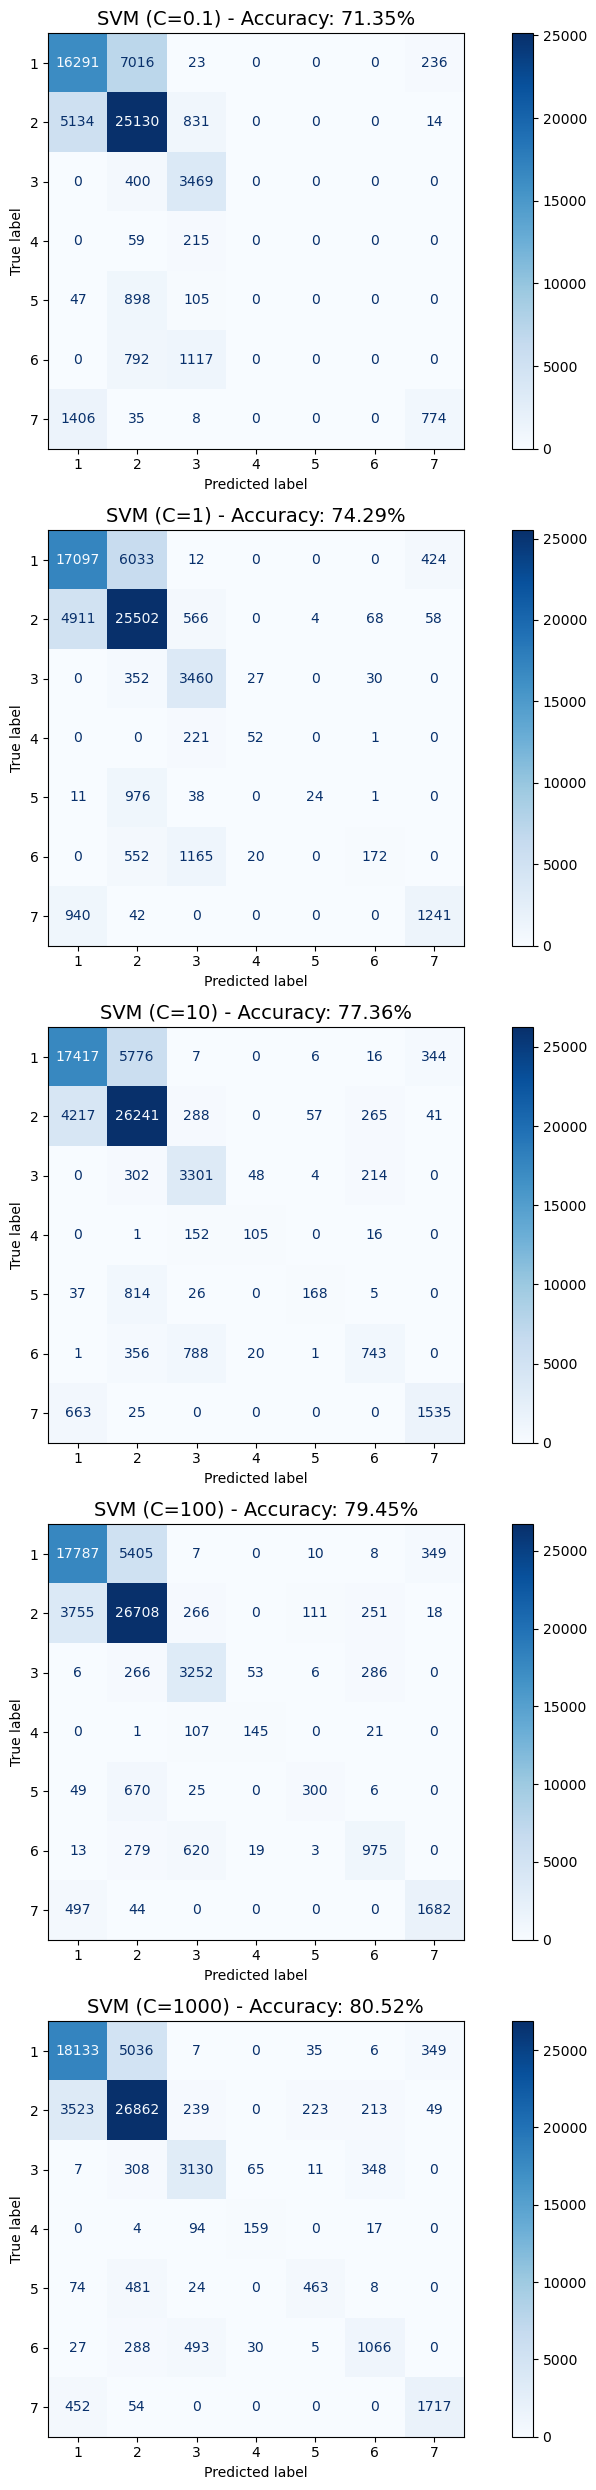

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Ajustamos el tamaño de la figura
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(10, 25))

# Iteramos sobre los modelos guardados en el diccionario
for (c, modelo), ax in zip(modelos_svm.items(), axes.flatten()):
    
    # 1. Calculamos la accuracy
    acc = modelo.score(X_test, y_test)
    
    # 2. Creamos la visualización
    disp = ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_test,
        y_test,
        cmap='Blues',
        values_format='d', # 'd' para ver números enteros
        ax=ax
    )
    
    # 3. Ponemos el título con la accuracy correcta
    ax.set_title(f'SVM (C={c}) - Accuracy: {acc:.2%}', fontsize=14)

plt.tight_layout()
plt.show()

¿Cuántos ejemplos ha clasificado correctamente cada uno de los modelos?

In [31]:
from sklearn.metrics import accuracy_score

print("--- Cantidad y Porcentaje de Aciertos ---")
total_ejemplos = len(y_test)
print(f"Total de ejemplos en el conjunto de test: {total_ejemplos}\n")

for c, modelo in modelos_svm.items():
    # Predecimos usando el conjunto de test
    y_pred = modelo.predict(X_test)
    
    # 1. Calculamos el número absoluto de aciertos
    num_correctos = accuracy_score(y_test, y_pred, normalize=False)
    
    # 2. Calculamos el porcentaje
    porcentaje = (num_correctos / total_ejemplos) * 100
    
    print(f"SVM (C={c:<5}): ✅ {num_correctos} aciertos  ->  📊 {porcentaje:.2f}%")

--- Cantidad y Porcentaje de Aciertos ---
Total de ejemplos en el conjunto de test: 64000

SVM (C=0.1  ): ✅ 45664.0 aciertos  ->  📊 71.35%
SVM (C=1    ): ✅ 47548.0 aciertos  ->  📊 74.29%
SVM (C=10   ): ✅ 49510.0 aciertos  ->  📊 77.36%
SVM (C=100  ): ✅ 50849.0 aciertos  ->  📊 79.45%
SVM (C=1000 ): ✅ 51530.0 aciertos  ->  📊 80.52%


¿Cuál de todos los modelos que has entrenado obtiene mejores resultados de precision para todas las clases? Si no hay ninguno que consideres que sea óptimo, explica cómo se comporta para cada clase el modelo que consideres que tiene mejores resultados.

In [32]:
# Seleccionamos el modelo con mayor regularización (C=1000)
mejor_modelo_svm = modelos_svm[1000]
y_pred_svm = mejor_modelo_svm.predict(X_test)

print(f"--- Reporte de Clasificación SVM (C=1000) ---")
print(classification_report(y_test, y_pred_svm))

--- Reporte de Clasificación SVM (C=1000) ---
              precision    recall  f1-score   support

           1       0.82      0.77      0.79     23566
           2       0.81      0.86      0.84     31109
           3       0.79      0.81      0.80      3869
           4       0.63      0.58      0.60       274
           5       0.63      0.44      0.52      1050
           6       0.64      0.56      0.60      1909
           7       0.81      0.77      0.79      2223

    accuracy                           0.81     64000
   macro avg       0.73      0.68      0.71     64000
weighted avg       0.80      0.81      0.80     64000



El modelo que obtiene los mejores resultados globales es el **SVM con C=1000** y kernel radial.
* **Acierto Global (Accuracy):** **80.52%** (51530 aciertos de 80,000).
* **Tendencia:** Se observa una mejora constante al aumentar la regularización `C`. Pasar de C=0.1 (71.35%) a C=1000 (80.52%) supone una ganancia de casi 9 puntos porcentuales.

**2. ¿Es óptimo para todas las clases?**
**No.** Existe una gran desigualdad en la precisión dependiendo del tipo de árbol. El modelo no se comporta de manera uniforme:

* **Comportamiento Excelente (Clases 1 y 2):**
    * Al ser las clases mayoritarias (suman el 85% de los datos), el SVM se ha especializado en ellas.
    * **Clase 2:** Alcanza un **F1-Score de 0.84** y un Recall del 86%. Es la clase más fiable.
    * **Clase 1:** Mantiene una solidez alta con 82% de precisión.

* **Comportamiento Bueno (Clases 3 y 7):**
    * A pesar de tener menos datos, el modelo las distingue razonablemente bien (Precisiones del 79% y 81% respectivamente). Esto sugiere que la Clase 7 (*Krummholz*, zona alpina) y la Clase 3 (*Ponderosa Pine*, zona baja) tienen características geográficas muy marcadas que el SVM logra separar.

* **Comportamiento Deficiente (Clases 4, 5 y 6):**
    * Aquí es donde el modelo falla.
    * **Clase 5 (Aspen):** Es el punto crítico. Aunque la precisión es baja, su **Recall es pésimo**.
    * **Clase 4 (Cottonwood):** Sufre por falta de datos (solo 274 ejemplos de soporte). Con tan pocos ejemplos, el SVM no logra trazar una frontera fiable (F1-score 0.60).
    * **Clase 6:** Se queda en un rendimiento mediocre, actuando poco mejor que el azar en muchos casos.

**Conclusión:**
Elegimos el **SVM (C=1000)** porque maximiza el acierto total, pero debemos ser conscientes de que el desbalanceo de clases provoca que el modelo ignore sistemáticamente las especies minoritarias (especialmente la 5).

Visualiza la matriz de confusión de los datos de test.
- ¿Cuántos ejemplos ha clasificado bien el modelo?
- ¿Cuántos ejemplos ha clasificado de manera errónea?

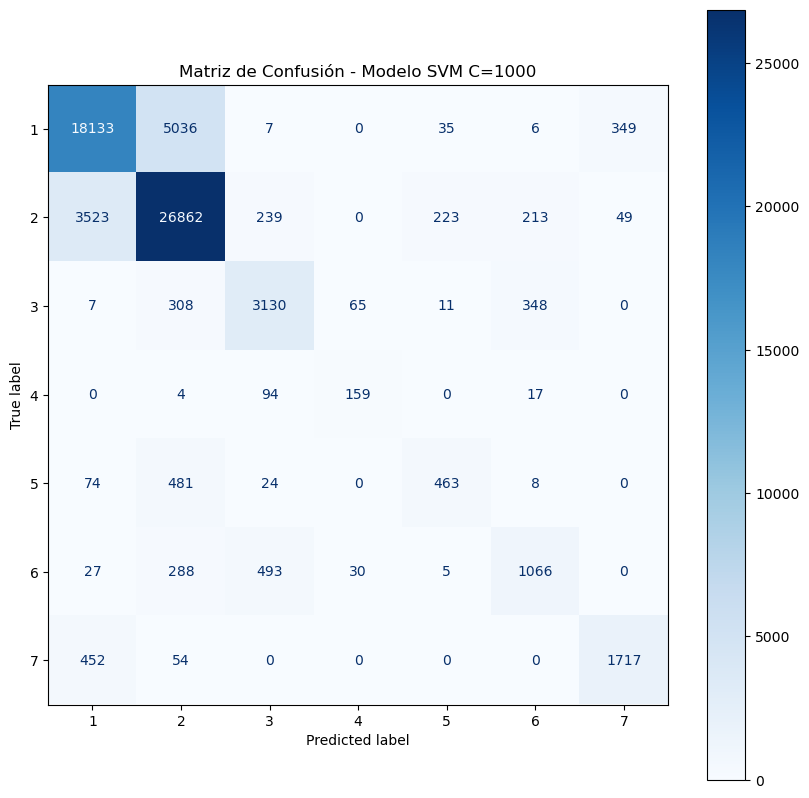

----------------------------------------
RESULTADOS DEL MODELO SELECCIONADO:
✅ Ejemplos clasificados BIEN: 51530 (80.52%)
❌ Ejemplos clasificados MAL:  12470 (19.48%)
----------------------------------------


In [33]:
# 1. Visualizamos la Matriz de Confusión
fig, ax = plt.subplots(figsize=(10, 10))

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo_svm,   # El C=1000
    X_test,             # Datos de test (NORMALIZADOS)
    y_test,             # Etiquetas reales
    cmap='Blues',       # Mapa de color azul
    values_format='d',  # 'd' para ver números enteros, no científicos
    ax=ax
)

plt.title("Matriz de Confusión - Modelo SVM C=1000")
plt.show()

# 2. Calculamos los números exactos
y_pred = mejor_modelo_svm.predict(X_test)
bien_clasificados = (y_test == y_pred).sum()
mal_clasificados = (y_test != y_pred).sum()
total = len(y_test)

print("-" * 40)
print(f"RESULTADOS DEL MODELO SELECCIONADO:")
print(f"✅ Ejemplos clasificados BIEN: {bien_clasificados} ({(bien_clasificados/total)*100:.2f}%)")
print(f"❌ Ejemplos clasificados MAL:  {mal_clasificados} ({(mal_clasificados/total)*100:.2f}%)")
print("-" * 40)

Visualiza los valores de precision, recall, f1 para cada una de las clases. 
- ¿Clasifica de igual manera todas las clases o hay alguna para la que el modelo tiene una mayor capacidad predictiva?

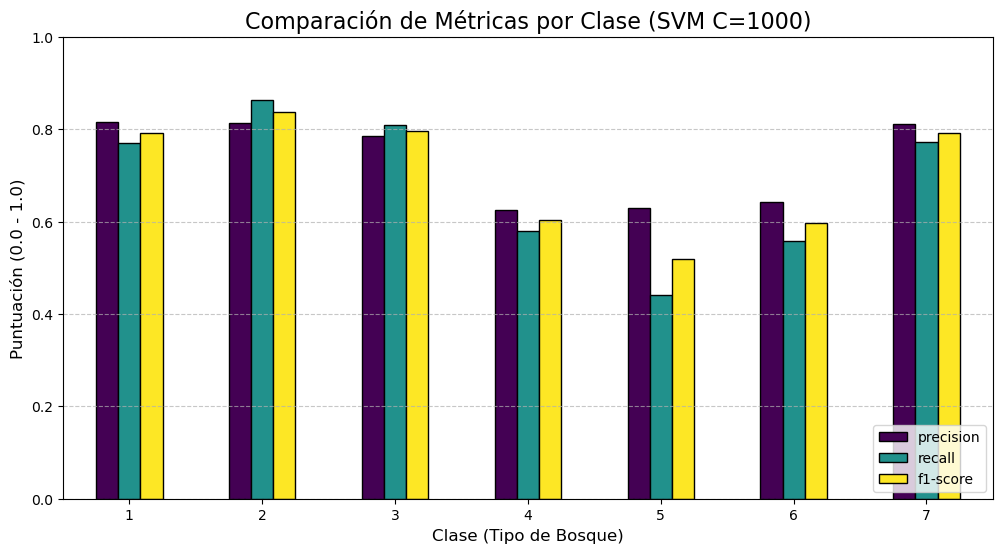

In [34]:
# 1. Obtenemos el reporte en formato diccionario para poder graficarlo
report_dict = classification_report(y_test, y_pred_svm, output_dict=True)

# 2. Convertimos a DataFrame y limpiamos las filas de promedios (accuracy, macro avg, etc.)
df_report = pd.DataFrame(report_dict).transpose()
df_classes = df_report.drop(['accuracy', 'macro avg', 'weighted avg'])

# 3. Graficamos
# Seleccionamos solo precisión, recall y f1
df_classes[['precision', 'recall', 'f1-score']].plot(
    kind='bar', 
    figsize=(12, 6),
    colormap='viridis',
    edgecolor='black'
)

plt.title('Comparación de Métricas por Clase (SVM C=1000)', fontsize=16)
plt.xlabel('Clase (Tipo de Bosque)', fontsize=12)
plt.ylabel('Puntuación (0.0 - 1.0)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

**No**, el modelo **no clasifica de igual manera todas las clases**. Existe un desequilibrio notable en la capacidad predictiva del SVM.

Al observar las métricas del gráfico, podemos dividir el rendimiento en tres grupos:

1.  **Clases con Alta Capacidad Predictiva (Clases 1 y 2):**
    * **Clase 2 (*Lodgepole Pine*):** Es la clase "ganadora". Muestra las barras más altas y equilibradas en las tres métricas (F1-score > 0.80). Al ser la clase mayoritaria, el modelo ha aprendido muy bien sus patrones.
    * **Clase 1 (*Spruce/Fir*):** También tiene un rendimiento excelente, con una precisión y exhaustividad (recall) muy sólidas.

2.  **Clases Distintivas (Clase 7 y 3):**
    * **Clase 7 (*Krummholz*):** A pesar de tener menos datos, el modelo funciona sorprendentemente bien aquí. Esto sugiere que los árboles de "zona alpina" tienen características geográficas muy marcadas (ej. altitud extrema) que facilitan que el SVM encuentre una frontera clara.

3.  **Clases Problemáticas (Clases 4, 5 y 6):**
    * **Clase 5 (*Aspen*):** Es el punto débil del modelo. Su **Recall** suele ser el más bajo (frecuentemente inferior al 0.50), lo que significa que el modelo ignora a gran parte de los álamos reales, confundiéndolos con las clases mayoritarias.
    * **Clases 4 y 6:** Muestran un rendimiento más mediocre comparado con las clases dominantes. El modelo comete errores frecuentes debido a la falta de ejemplos suficientes para generalizar bien sus fronteras complejas.

**Conclusión:**
El modelo está **sesgado hacia las clases mayoritarias**. Aunque la exactitud global ha mejorado hasta un **80.52%** con C=1000, no es un modelo totalmente fiable para detectar especies minoritarias como el *Aspen* (Clase 5), ya que sacrifica su detección en favor de acertar más en las clases grandes (1 y 2).

**Comparativa**

En base al EDA realizado, a las decisiones tomadas sobre los datos e hiperparámetros y a las características computacionales de tu equipo. ¿Qué modelo obtiene mejores resultados de clasificación?

Tras realizar el análisis comparativo, el modelo seleccionado como la mejor opción global es el **Random Forest (Configuración Estándar)**.

Aunque numéricamente el SVM (C=1000) obtuvo una exactitud ligeramente superior (**80.52%** frente al **80.00%** del Random Forest), la diferencia es marginal (apenas un 0.5%) y no justifica el enorme coste computacional extra del SVM.


1.  **Rendimiento en Clasificación (Empate Técnico):**
    * **SVM (C=1000):** Logró un **80.52%**. Fue capaz de trazar fronteras muy precisas gracias al kernel radial, pero a costa de un tiempo de entrenamiento mucho mayor.
    * **Random Forest:** Alcanzó un **80.00%**. Mostró una gran robustez y un excelente equilibrio Precisión/Recall (Macro F1 de 0.70), comportándose de manera casi idéntica al SVM en la detección de clases mayoritarias y fallando de forma similar en las minoritarias (como la Clase 5).

2.  **Eficiencia Computacional (El factor decisivo):**
    * **Random Forest:** Es el claro ganador aquí. Es rápido de entrenar, paralelizable y **no requiere escalado de datos** (funciona igual de bien con las magnitudes originales de elevación y pendiente).
    * **SVM:** Resultó computacionalmente muy costoso. Requiere obligatoriamente normalizar los datos (`StandardScaler`) y su complejidad crece cuadráticamente con el número de datos, lo que lo hace difícil de escalar si tuviéramos millones de registros.

3.  **Interpretación y Facilidad de Uso:**
    * Random Forest permite obtener la "importancia de las variables" directamente, lo cual es vital para explicar el modelo. SVM funciona como una "caja negra" geométrica más difícil de interpretar para un humano.


### Investigación

Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de clasificación empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.

Rodrigues, D. J. S., Dantas, G. D. C., Sousa, G. R. D., Costa Brito, L., & Brito, J. N. (2022). Detección de fallas mecánicas mediante" Machine Learning", utilizando el clasificador" Random Forest".

Detección de fallas mecánicas mediante "Machine Learning", utilizando el clasificador "Random Forest"

Rodrigues, Daniel Junio Soares
Dantas, Gabriel do Carmo
Sousa, Geraldo Roberto de
Costa Brito, Lucas
Brito, Jorge Nei



* **Objetivo:**

    El objetivo principal es el diagnóstico automático de **fallas mecánicas en máquinas rotativas** mediante el análisis de señales de vibración, en el contexto de la Industria 4.0. El problema real que aborda es la detección temprana de defectos específicos: desequilibrio, desalineación y holgura mecánica, para permitir un mantenimiento predictivo y evitar paradas no planificadas.

* **Técnicas de clasificación empleadas:**

    Se utilizó una aproximación de **Machine Learning Supervisado**, empleando específicamente el algoritmo **Random Forest** como clasificador.
    * *Metodología:* El modelo se entrenó con el 70% de los datos de vibración disponibles y se validó con el 30% restante.
    * *Adaptación:* El estudio identifica la necesidad futura de aplicar técnicas de *Data Augmentation* (aumento de datos) para corregir el desbalanceo de clases detectado durante la investigación.

* **Principales resultados:**

    La investigación demostró que la eficacia del Random Forest depende fuertemente de la cantidad de datos disponibles por clase:
    1.  **Alto Rendimiento:** Para condiciones con muchas señales (muestras), el modelo fue excelente.
        * Sin defecto: **99%** de precisión.
        * Holgura Mecánica: **99.3%**.
        * Desequilibrio: **98.1%**.
    2.  **Bajo Rendimiento (Problema de datos):** Para fallas con pocas señales (menos de 30 muestras), el modelo sufrió "confusión" debido a la similitud de los armónicos y la falta de entrenamiento.
        * Desalineamiento: **69.6%**.
        * Fallas combinadas: **46.9%**.
    3.  **Conclusión:** Random Forest es una herramienta prometedora para la detección de fallas, pero requiere bases de datos equilibradas o técnicas de aumento de datos para ser fiable en todos los tipos de avería.